import necessary library

In [78]:
import pandas as pd
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler, LabelEncoder,StandardScaler, RobustScaler, MaxAbsScaler,FunctionTransformer,OneHotEncoder
from pandas.api.types import is_numeric_dtype

see the freely available datasets

In [42]:
sns.get_dataset_names()

['anagrams',
 'anscombe',
 'attention',
 'brain_networks',
 'car_crashes',
 'diamonds',
 'dots',
 'dowjones',
 'exercise',
 'flights',
 'fmri',
 'geyser',
 'glue',
 'healthexp',
 'iris',
 'mpg',
 'penguins',
 'planets',
 'seaice',
 'taxis',
 'tips',
 'titanic']

load datasets

In [43]:
df = sns.load_dataset("car_crashes")

In [44]:
df.head()

,total,speeding,alcohol,not_distracted,no_previous,ins_premium,ins_losses,abbrev
0,18.8,7.332,5.640,18.048,15.040,784.55,145.08,AL
1,18.1,7.421,4.525,16.290,17.014,1053.48,133.93,AK
2,18.6,6.510,5.208,15.624,17.856,899.47,110.35,AZ
3,22.4,4.032,5.824,21.056,21.280,827.34,142.39,AR
4,12.0,4.200,3.360,10.920,10.680,878.41,165.63,CA


In [45]:
df.shape

(51, 8)

In [46]:
df.duplicated().sum()

np.int64(0)

i got a total of 51 rows ans 8 columns where there is no duplicate value found

In [47]:
df.isna().sum()

total             0
speeding          0
alcohol           0
not_distracted    0
no_previous       0
ins_premium       0
ins_losses        0
abbrev            0
dtype: int64

In [48]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 51 entries, 0 to 50
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   total           51 non-null     float64
 1   speeding        51 non-null     float64
 2   alcohol         51 non-null     float64
 3   not_distracted  51 non-null     float64
 4   no_previous     51 non-null     float64
 5   ins_premium     51 non-null     float64
 6   ins_losses      51 non-null     float64
 7   abbrev          51 non-null     object 
dtypes: float64(7), object(1)
memory usage: 3.3+ KB


In [49]:
df.describe()

,total,speeding,alcohol,not_distracted,no_previous,ins_premium,ins_losses
count,51.000000,51.000000,51.000000,51.000000,51.000000,51.000000,51.000000
mean,15.790196,4.998196,4.886784,13.573176,14.004882,886.957647,134.493137
std,4.122002,2.017747,1.729133,4.508977,3.764672,178.296285,24.835922
min,5.900000,1.792000,1.593000,1.760000,5.900000,641.960000,82.750000
25%,12.750000,3.766500,3.894000,10.478000,11.348000,768.430000,114.645000
50%,15.600000,4.608000,4.554000,13.857000,13.775000,858.970000,136.050000
75%,18.500000,6.439000,5.604000,16.140000,16.755000,1007.945000,151.870000
max,23.900000,9.450000,10.038000,23.661000,21.280000,1301.520000,194.780000


In [50]:
df.columns

Index(['total', 'speeding', 'alcohol', 'not_distracted', 'no_previous',
       'ins_premium', 'ins_losses', 'abbrev'],
      dtype='object')

Data Preprocessing

apply label encoding on abbrev

In [51]:
le = LabelEncoder()
df["abbrev"]= le.fit_transform(df["abbrev"])
df.head()

,total,speeding,alcohol,not_distracted,no_previous,ins_premium,ins_losses,abbrev
0,18.8,7.332,5.640,18.048,15.040,784.55,145.08,1
1,18.1,7.421,4.525,16.290,17.014,1053.48,133.93,0
2,18.6,6.510,5.208,15.624,17.856,899.47,110.35,3
3,22.4,4.032,5.824,21.056,21.280,827.34,142.39,2
4,12.0,4.200,3.360,10.920,10.680,878.41,165.63,4


In [52]:
df.corr()

,total,speeding,alcohol,not_distracted,no_previous,ins_premium,ins_losses,abbrev
total,1.000000,0.611548,0.852613,0.827560,0.956179,-0.199702,-0.036011,0.043213
speeding,0.611548,1.000000,0.669719,0.588010,0.571976,-0.077675,-0.065928,0.079701
alcohol,0.852613,0.669719,1.000000,0.732816,0.783520,-0.170612,-0.112547,0.135754
not_distracted,0.827560,0.588010,0.732816,1.000000,0.747307,-0.174856,-0.075970,0.004800
no_previous,0.956179,0.571976,0.783520,0.747307,1.000000,-0.156895,-0.006359,-0.029075
ins_premium,-0.199702,-0.077675,-0.170612,-0.174856,-0.156895,1.000000,0.623116,-0.175018
ins_losses,-0.036011,-0.065928,-0.112547,-0.075970,-0.006359,0.623116,1.000000,-0.134035
abbrev,0.043213,0.079701,0.135754,0.004800,-0.029075,-0.175018,-0.134035,1.000000


<Axes: >

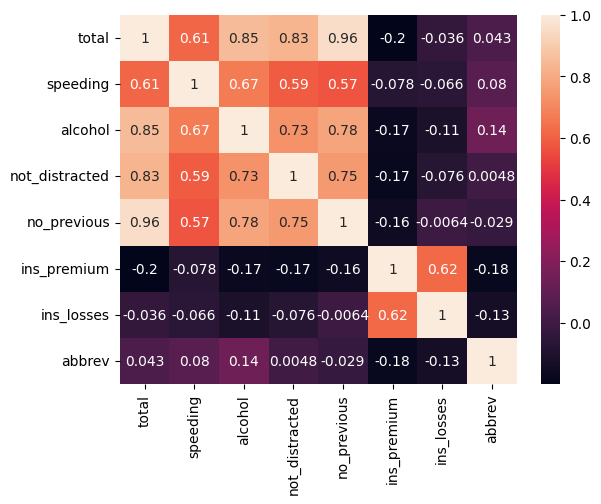

In [53]:
sns.heatmap(df.corr(), annot=True)

apply min max scaler 

In [54]:
df.head(2)

,total,speeding,alcohol,not_distracted,no_previous,ins_premium,ins_losses,abbrev
0,18.8,7.332,5.640,18.048,15.040,784.55,145.08,1
1,18.1,7.421,4.525,16.290,17.014,1053.48,133.93,0


In [55]:
min_max= MinMaxScaler()

df["speeding"]= min_max.fit_transform(df[["speeding"]])

In [56]:
df.head(2)

,total,speeding,alcohol,not_distracted,no_previous,ins_premium,ins_losses,abbrev
0,18.8,0.723426,5.640,18.048,15.040,784.55,145.08,1
1,18.1,0.735048,4.525,16.290,17.014,1053.48,133.93,0


change  MinMaxScaler() parameter

In [57]:
min_max_up= MinMaxScaler(feature_range=(1,5))

In [58]:
df["speeding"]= min_max_up.fit_transform(df[["speeding"]])
df.head(2)

,total,speeding,alcohol,not_distracted,no_previous,ins_premium,ins_losses,abbrev
0,18.8,3.893706,5.640,18.048,15.040,784.55,145.08,1
1,18.1,3.940193,4.525,16.290,17.014,1053.48,133.93,0


In [59]:
df.head() # data reload again 

,total,speeding,alcohol,not_distracted,no_previous,ins_premium,ins_losses,abbrev
0,18.8,3.893706,5.640,18.048,15.040,784.55,145.08,1
1,18.1,3.940193,4.525,16.290,17.014,1053.48,133.93,0
2,18.6,3.464351,5.208,15.624,17.856,899.47,110.35,3
3,22.4,2.170018,5.824,21.056,21.280,827.34,142.39,2
4,12.0,2.257770,3.360,10.920,10.680,878.41,165.63,4


In [60]:
x = df.drop(["total"], axis=1)
x.head()

,speeding,alcohol,not_distracted,no_previous,ins_premium,ins_losses,abbrev
0,3.893706,5.640,18.048,15.040,784.55,145.08,1
1,3.940193,4.525,16.290,17.014,1053.48,133.93,0
2,3.464351,5.208,15.624,17.856,899.47,110.35,3
3,2.170018,5.824,21.056,21.280,827.34,142.39,2
4,2.257770,3.360,10.920,10.680,878.41,165.63,4


In [61]:
y = df[["total"]]
y.head()

,total
0,18.8
1,18.1
2,18.6
3,22.4
4,12.0


In [62]:
for col in x.columns:
     if is_numeric_dtype(x[col]):
          x[col]= min_max.fit_transform(x[[col]])
     else:
          x[col]= le.fit_transform(x[col])

In [63]:
x.head()

,speeding,alcohol,not_distracted,no_previous,ins_premium,ins_losses,abbrev
0,0.723426,0.479218,0.743710,0.594278,0.216190,0.556369,0.02
1,0.735048,0.347188,0.663440,0.722627,0.623931,0.456842,0.00
2,0.616088,0.428064,0.633030,0.777373,0.390427,0.246363,0.06
3,0.292505,0.501007,0.881056,1.000000,0.281066,0.532357,0.04
4,0.314442,0.209236,0.418246,0.310793,0.358497,0.739802,0.08


In [64]:
# standard scaler
# log transform
# robust scaler
# max absoulte scaler 
# one hot encoding problem

# standard scaler 

In [65]:
std = StandardScaler()
df["alcohol"]= std.fit_transform(df[["alcohol"]])
df.head(2)


,total,speeding,alcohol,not_distracted,no_previous,ins_premium,ins_losses,abbrev
0,18.8,3.893706,0.439938,18.048,15.040,784.55,145.08,1
1,18.1,3.940193,-0.211311,16.290,17.014,1053.48,133.93,0


In [66]:
df["alcohol"].mean()

np.float64(-1.730641773680391e-16)

In [67]:
df["alcohol"].std()

np.float64(1.0099504938362076)

In [68]:
(.43- df["alcohol"].mean())/df["alcohol"].std()

np.float64(0.4257634434799702)

# max absoulte scaler 

In [69]:
max_abs= MaxAbsScaler()
df["not_distracted"]= max_abs.fit_transform(df[["not_distracted"]])
df.head(2)

,total,speeding,alcohol,not_distracted,no_previous,ins_premium,ins_losses,abbrev
0,18.8,3.893706,0.439938,0.762774,15.040,784.55,145.08,1
1,18.1,3.940193,-0.211311,0.688475,17.014,1053.48,133.93,0


# robust scaler

In [70]:
q1 = df["no_previous"].quantile(.25)
q2 = df["no_previous"].median()
q3 = df["no_previous"].quantile(.75)
iqr = q3 - q1

In [71]:
(15.040 - q2)/iqr

np.float64(0.23395598298501918)

In [72]:
rbs= RobustScaler()
df["no_previous"]= rbs.fit_transform(df[["no_previous"]])
df.head(2)

,total,speeding,alcohol,not_distracted,no_previous,ins_premium,ins_losses,abbrev
0,18.8,3.893706,0.439938,0.762774,0.233956,784.55,145.08,1
1,18.1,3.940193,-0.211311,0.688475,0.599038,1053.48,133.93,0


# log transform 

In [74]:
import numpy as np

In [75]:
ft = FunctionTransformer(func=np.log1p, inverse_func=np.expm1)

In [76]:
df["ins_losses"]= ft.fit_transform(df[["ins_losses"]])
df.head(2)

,total,speeding,alcohol,not_distracted,no_previous,ins_premium,ins_losses,abbrev
0,18.8,3.893706,0.439938,0.762774,0.233956,784.55,4.984154,1
1,18.1,3.940193,-0.211311,0.688475,0.599038,1053.48,4.904756,0


# one hot encoding problem

In [83]:
df1 = sns.load_dataset("titanic")

In [90]:
oht = OneHotEncoder(sparse_output=False)

In [95]:
df1["embark_town"].value_counts()

embark_town
Southampton    644
Cherbourg      168
Queenstown      77
Name: count, dtype: int64

In [92]:
df1.shape

(891, 15)

In [96]:
df1["embark_town"]= oht.fit_transform(df1[["embark_town"]])
df1.head(2)

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,0.0,22.0,1,0,7.2500,S,Third,man,True,NaN,0.0,no,False
1,1,1,1.0,38.0,1,0,71.2833,C,First,woman,False,C,1.0,yes,False


In [97]:
df1["embark_town"].value_counts()

embark_town
0.0    723
1.0    168
Name: count, dtype: int64

In [98]:
df1["class"].value_counts()

class
Third     491
First     216
Second    184
Name: count, dtype: int64

In [100]:
encode = oht.fit_transform(df1[["class"]])
encode

array([[0., 0., 1.],
       [1., 0., 0.],
       [0., 0., 1.],
       ...,
       [0., 0., 1.],
       [1., 0., 0.],
       [0., 0., 1.]], shape=(891, 3))

In [101]:
df = pd.DataFrame(encode, columns=oht.get_feature_names_out(["class"]))
df

,class_First,class_Second,class_Third
0,0.0,0.0,1.0
1,1.0,0.0,0.0
2,0.0,0.0,1.0
3,1.0,0.0,0.0
4,0.0,0.0,1.0
...,...,...,...
886,0.0,1.0,0.0
887,1.0,0.0,0.0
888,0.0,0.0,1.0
889,1.0,0.0,0.0


In [102]:
df1.drop(["class"], axis=1, inplace=True)
df1.head(2)

,survived,pclass,sex,age,sibsp,parch,fare,embarked,who,adult_male,deck,embark_town,alive,alone
0,0,3,0.0,22.0,1,0,7.2500,S,man,True,NaN,0.0,no,False
1,1,1,1.0,38.0,1,0,71.2833,C,woman,False,C,1.0,yes,False


In [104]:
new_df = pd.concat([df1, df], axis=1)

In [105]:
new_df

,survived,pclass,sex,age,sibsp,parch,fare,embarked,who,adult_male,deck,embark_town,alive,alone,class_First,class_Second,class_Third
0,0,3,0.0,22.0,1,0,7.2500,S,man,True,NaN,0.0,no,False,0.0,0.0,1.0
1,1,1,1.0,38.0,1,0,71.2833,C,woman,False,C,1.0,yes,False,1.0,0.0,0.0
2,1,3,1.0,26.0,0,0,7.9250,S,woman,False,NaN,0.0,yes,True,0.0,0.0,1.0
3,1,1,1.0,35.0,1,0,53.1000,S,woman,False,C,0.0,yes,False,1.0,0.0,0.0
4,0,3,0.0,35.0,0,0,8.0500,S,man,True,NaN,0.0,no,True,0.0,0.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,0,2,0.0,27.0,0,0,13.0000,S,man,True,NaN,0.0,no,True,0.0,1.0,0.0
887,1,1,1.0,19.0,0,0,30.0000,S,woman,False,B,0.0,yes,True,1.0,0.0,0.0
888,0,3,1.0,NaN,1,2,23.4500,S,woman,False,NaN,0.0,no,False,0.0,0.0,1.0
889,1,1,0.0,26.0,0,0,30.0000,C,man,True,C,1.0,yes,True,1.0,0.0,0.0


# dummy data creation 

In [106]:
df1.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,who,adult_male,deck,embark_town,alive,alone
0,0,3,0.0,22.0,1,0,7.2500,S,man,True,NaN,0.0,no,False
1,1,1,1.0,38.0,1,0,71.2833,C,woman,False,C,1.0,yes,False
2,1,3,1.0,26.0,0,0,7.9250,S,woman,False,NaN,0.0,yes,True
3,1,1,1.0,35.0,1,0,53.1000,S,woman,False,C,0.0,yes,False
4,0,3,0.0,35.0,0,0,8.0500,S,man,True,NaN,0.0,no,True


In [107]:
df1["who"].value_counts()

who
man      537
woman    271
child     83
Name: count, dtype: int64

In [111]:
dummy = pd.get_dummies(df1["who"], prefix="who",drop_first=True).astype("int64")
dummy

,who_man,who_woman
0,1,0
1,0,1
2,0,1
3,0,1
4,1,0
...,...,...
886,1,0
887,0,1
888,0,1
889,1,0


In [113]:
df1.drop(["who"], axis=1, inplace=True)

In [115]:
df1= pd.concat([df1, dummy], axis=1)
df1.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,adult_male,deck,embark_town,alive,alone,who_man,who_woman
0,0,3,0.0,22.0,1,0,7.2500,S,True,NaN,0.0,no,False,1,0
1,1,1,1.0,38.0,1,0,71.2833,C,False,C,1.0,yes,False,0,1
2,1,3,1.0,26.0,0,0,7.9250,S,False,NaN,0.0,yes,True,0,1
3,1,1,1.0,35.0,1,0,53.1000,S,False,C,0.0,yes,False,0,1
4,0,3,0.0,35.0,0,0,8.0500,S,True,NaN,0.0,no,True,1,0


In [117]:
x = df1.drop(["survived"], axis=1)
y = df1[["survived"]]

In [118]:
x.head()

,pclass,sex,age,sibsp,parch,fare,embarked,adult_male,deck,embark_town,alive,alone,who_man,who_woman
0,3,0.0,22.0,1,0,7.2500,S,True,NaN,0.0,no,False,1,0
1,1,1.0,38.0,1,0,71.2833,C,False,C,1.0,yes,False,0,1
2,3,1.0,26.0,0,0,7.9250,S,False,NaN,0.0,yes,True,0,1
3,1,1.0,35.0,1,0,53.1000,S,False,C,0.0,yes,False,0,1
4,3,0.0,35.0,0,0,8.0500,S,True,NaN,0.0,no,True,1,0


In [120]:
y.head()

,survived
0,0
1,1
2,1
3,1
4,0


In [119]:
x.shape, y.shape

((891, 14), (891, 1))